In [31]:


import torch
from torchvision import datasets, transforms
import tqdm.notebook as tqdm
import torch.nn as nn
from torch.utils.tensorboard import SummaryWriter
from torchsummary import summary

In [32]:
path = ('./DatasetSports40/Dataset/')
writer = SummaryWriter()
batch=32

# Data augmentation for training images
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.2),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


val_test_transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train = datasets.ImageFolder(path+'train',transform=transform_pipeline)
test = datasets.ImageFolder(path+'test', transform=val_test_transform_pipeline)
val = datasets.ImageFolder(path+'valid', transform=val_test_transform_pipeline)

train_loader = torch.utils.data.DataLoader(train, batch_size=batch, shuffle=True)
test_loader = torch.utils.data.DataLoader(test, batch_size=batch, shuffle=True)
val_loader = torch.utils.data.DataLoader(val, batch_size=batch, shuffle=True)

print(f"Number of classes in training dataset: {len(train.classes)}")
print(f"Number of classes in testing dataset: {len(test.classes)}")
print(f"Number of classes in validation dataset: {len(val.classes)}")

Number of classes in training dataset: 40
Number of classes in testing dataset: 40
Number of classes in validation dataset: 40


## Modelo 1.1: AlexNet com BatchNorm

In [33]:
lr = 0.005
num_epochs = 60
seed = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

# Criando um writer específico para o Modelo 1.1
writer_anet1 = SummaryWriter('runs/AlexNet_BatchNorm')

Anet = nn.Sequential(
                    nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=1), nn.BatchNorm2d(96),
                    nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),
                    nn.Conv2d(96,192, kernel_size=5, padding=2), nn.BatchNorm2d(192), nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),
                    nn.Conv2d(192, 256, kernel_size=3, padding=1),nn.BatchNorm2d(256), nn.ReLU(),
                    nn.Conv2d(256, 384, kernel_size=3, padding=1),nn.BatchNorm2d(384),nn.ReLU(),
                    nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256),nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),
                    nn.Flatten(),
                    nn.Linear(6400, 1024), nn.BatchNorm1d(1024),
                    nn.ReLU(),
                    nn.Dropout(p=0.5),
                    nn.Linear(1024, 512), nn.BatchNorm1d(512),
                    nn.ReLU(),
                    nn.Dropout(p=0.5),
                    nn.Linear(512, 40)
                    )

# Move the network to the GPU BEFORE calling summary
if device.type == 'cuda':
    torch.cuda.empty_cache()
Anet.to(device)

summary(Anet, (3, 224, 224))

loss = nn.CrossEntropyLoss()
optim = torch.optim.SGD(Anet.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=1, gamma=0.98)

for epoch in tqdm.tqdm(range(num_epochs)):

  Anet.train()
  for X,y in train_loader:
    # Move dados para GPU
    X, y = X.to(device), y.to(device)
    y_hat = Anet(X)
    l = loss(y_hat, y)
    optim.zero_grad()
    l.backward()
    optim.step()
  scheduler.step()

  Anet.eval()

  val_loss_total = 0.0
  val_corrects = 0
  val_total = 0

  with torch.no_grad():
    for x_val, y_val in val_loader:
        # Move dados de teste
        x_val, y_val = x_val.to(device), y_val.to(device)

        y_hat_val = Anet(x_val)
        l_test = loss(y_hat_val, y_val)
        val_loss_total += l_test.item() * x_val.size(0)

        # Conta os acertos deste batch
        predictions = torch.argmax(y_hat_val, dim=1)
        val_corrects += torch.sum(predictions == y_val).item()
        val_total += y_val.size(0)

  epoch_val_loss = val_loss_total / val_total
  epoch_val_acc = (val_corrects / val_total) * 100
  lr_last= scheduler.get_last_lr()[0]
  print(f'Epoch: {epoch} 	 Loss: {epoch_val_loss} 	 Acc: {epoch_val_acc}, 	 LR: {lr_last}')
  writer_anet1.add_scalar("Loss/test", l_test.item(), epoch)
  writer_anet1.add_scalar("Acc/test", epoch_val_acc, epoch)
  writer_anet1.add_scalar("LR", lr_last, epoch)
  writer_anet1.flush()

writer_anet1.close()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
       BatchNorm2d-2           [-1, 96, 54, 54]             192
              ReLU-3           [-1, 96, 54, 54]               0
         MaxPool2d-4           [-1, 96, 26, 26]               0
            Conv2d-5          [-1, 192, 26, 26]         460,992
       BatchNorm2d-6          [-1, 192, 26, 26]             384
              ReLU-7          [-1, 192, 26, 26]               0
         MaxPool2d-8          [-1, 192, 12, 12]               0
            Conv2d-9          [-1, 256, 12, 12]         442,624
      BatchNorm2d-10          [-1, 256, 12, 12]             512
             ReLU-11          [-1, 256, 12, 12]               0
           Conv2d-12          [-1, 384, 12, 12]         885,120
      BatchNorm2d-13          [-1, 384, 12, 12]             768
             ReLU-14          [-1, 384,

  0%|          | 0/60 [00:00<?, ?it/s]

Epoch: 0 	 Loss: 3.1563144969940184 	 Acc: 16.5, 	 LR: 0.0049
Epoch: 1 	 Loss: 2.8123890113830567 	 Acc: 30.0, 	 LR: 0.004802
Epoch: 2 	 Loss: 2.5575256729125977 	 Acc: 35.5, 	 LR: 0.0047059599999999995
Epoch: 3 	 Loss: 2.38531530380249 	 Acc: 39.0, 	 LR: 0.004611840799999999
Epoch: 4 	 Loss: 2.254352397918701 	 Acc: 40.5, 	 LR: 0.004519603983999999
Epoch: 5 	 Loss: 2.1915569496154785 	 Acc: 39.5, 	 LR: 0.004429211904319999
Epoch: 6 	 Loss: 1.9974356555938722 	 Acc: 44.0, 	 LR: 0.004340627666233598
Epoch: 7 	 Loss: 1.8553830194473266 	 Acc: 44.0, 	 LR: 0.004253815112908926
Epoch: 8 	 Loss: 1.9272844171524048 	 Acc: 47.5, 	 LR: 0.004168738810650748
Epoch: 9 	 Loss: 1.7570472240447998 	 Acc: 49.5, 	 LR: 0.004085364034437733
Epoch: 10 	 Loss: 1.6691098928451538 	 Acc: 51.0, 	 LR: 0.0040036567537489786
Epoch: 11 	 Loss: 1.6713049459457396 	 Acc: 48.5, 	 LR: 0.003923583618673999
Epoch: 12 	 Loss: 1.5130224704742432 	 Acc: 58.5, 	 LR: 0.003845111946300519
Epoch: 13 	 Loss: 1.4414529991149903

In [34]:
torch.save(Anet.state_dict(),'./models/Anet-final-1.pth')

## Modelo 1.2: AlexNet + Inception com Batch Norm

In [35]:
lr = 0.005
num_epochs = 60
seed = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

# Criando um writer específico para o Modelo 1.2
writer_anet2 = SummaryWriter('runs/AlexNet_Inception')

class Inception(nn.Module):
  def __init__(self,c1,c2,c3,c4, **kwargs):
      super(Inception, self).__init__(**kwargs)

      #Ramo 1:
      self.ramo1_1 = nn.LazyConv2d(c1, kernel_size=1)

      #Ramo 2
      self.ramo2_1 = nn.LazyConv2d(c2[0], kernel_size=1)
      self.ramo2_2 = nn.LazyConv2d(c2[1], kernel_size=3, padding=1)

      #Ramo3
      self.ramo3_1 = nn.LazyConv2d(c3[0], kernel_size=1)
      self.ramo3_2 = nn.LazyConv2d(c3[1], kernel_size=5, padding=2)

      #Ramo4
      self.ramo4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
      self.ramo4_2 = nn.LazyConv2d(c4, kernel_size=1)

  def forward(self, X):
      ramo1 = nn.functional.relu(self.ramo1_1(X))
      ramo2 = nn.functional.relu(self.ramo2_2(nn.functional.relu(self.ramo2_1(X))))
      ramo3 = nn.functional.relu(self.ramo3_2(nn.functional.relu(self.ramo3_1(X))))
      ramo4 = nn.functional.relu(self.ramo4_2(self.ramo4_1(X)))
      return torch.cat((ramo1, ramo2, ramo3, ramo4), dim=1)


Anet2 = nn.Sequential(
                    nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=1), nn.BatchNorm2d(96),
                    nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),
                    nn.Conv2d(96,192, kernel_size=5, padding=2), nn.BatchNorm2d(192), nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),
                    nn.Conv2d(192, 256, kernel_size=3, padding=1),nn.BatchNorm2d(256), nn.ReLU(),
                    nn.Conv2d(256, 384, kernel_size=3, padding=1),nn.BatchNorm2d(384),nn.ReLU(),
                    nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256),nn.ReLU(),
                    nn.MaxPool2d(kernel_size=3, stride=2),

                    Inception(64, (96, 128), (16, 32), 32),
                    nn.Flatten(),
                    nn.Linear(6400, 1024), nn.BatchNorm1d(1024),  # Corrigido de 12000 para 6400
                    nn.ReLU(),
                    nn.Dropout(p=0.5),
                    nn.Linear(1024, 512), nn.BatchNorm1d(512),
                    nn.ReLU(),
                    nn.Dropout(p=0.5),
                    nn.Linear(512, 40)
                    )


if device.type == 'cuda':
    torch.cuda.empty_cache()
Anet2.to(device)

summary(Anet2, (3, 224, 224))

loss = nn.CrossEntropyLoss()
optim = torch.optim.SGD(Anet2.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=1, gamma=0.98)

for epoch in tqdm.tqdm(range(num_epochs)):

  Anet2.train()
  for X,y in train_loader:
    # Move data to the GPU
    X, y = X.to(device), y.to(device)
    y_hat = Anet2(X)
    l = loss(y_hat, y)
    optim.zero_grad()
    l.backward()
    optim.step()
  scheduler.step()

  Anet2.eval()

  val_loss_total = 0.0
  val_corrects = 0
  val_total = 0

  with torch.no_grad():
    for x_val, y_val in val_loader:

        x_val, y_val = x_val.to(device), y_val.to(device)

        y_hat_val = Anet2(x_val)
        l_test = loss(y_hat_val, y_val)
        val_loss_total += l_test.item() * x_val.size(0)


        predictions = torch.argmax(y_hat_val, dim=1)
        val_corrects += torch.sum(predictions == y_val).item()
        val_total += y_val.size(0)

  epoch_val_loss = val_loss_total / val_total
  epoch_val_acc = (val_corrects / val_total) * 100
  lr_last= scheduler.get_last_lr()[0]
  print(f'Epoch: {epoch} 	 Loss: {epoch_val_loss} 	 Acc: {epoch_val_acc}, 	 LR: {lr_last}')
  writer_anet2.add_scalar("Loss/test", l_test.item(), epoch)
  writer_anet2.add_scalar("Acc/test", epoch_val_acc, epoch)
  writer_anet2.add_scalar("LR", lr_last, epoch)
  writer_anet2.flush()

writer_anet2.close()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
       BatchNorm2d-2           [-1, 96, 54, 54]             192
              ReLU-3           [-1, 96, 54, 54]               0
         MaxPool2d-4           [-1, 96, 26, 26]               0
            Conv2d-5          [-1, 192, 26, 26]         460,992
       BatchNorm2d-6          [-1, 192, 26, 26]             384
              ReLU-7          [-1, 192, 26, 26]               0
         MaxPool2d-8          [-1, 192, 12, 12]               0
            Conv2d-9          [-1, 256, 12, 12]         442,624
      BatchNorm2d-10          [-1, 256, 12, 12]             512
             ReLU-11          [-1, 256, 12, 12]               0
           Conv2d-12          [-1, 384, 12, 12]         885,120
      BatchNorm2d-13          [-1, 384, 12, 12]             768
             ReLU-14          [-1, 384,

  0%|          | 0/60 [00:00<?, ?it/s]

Epoch: 0 	 Loss: 3.094195852279663 	 Acc: 21.0, 	 LR: 0.0049
Epoch: 1 	 Loss: 2.7411076641082763 	 Acc: 30.0, 	 LR: 0.004802
Epoch: 2 	 Loss: 2.5238010406494142 	 Acc: 36.0, 	 LR: 0.0047059599999999995
Epoch: 3 	 Loss: 2.289558353424072 	 Acc: 40.5, 	 LR: 0.004611840799999999
Epoch: 4 	 Loss: 2.111749210357666 	 Acc: 40.0, 	 LR: 0.004519603983999999
Epoch: 5 	 Loss: 2.0162040328979494 	 Acc: 45.5, 	 LR: 0.004429211904319999
Epoch: 6 	 Loss: 1.8574515438079835 	 Acc: 50.0, 	 LR: 0.004340627666233598
Epoch: 7 	 Loss: 1.7606892251968385 	 Acc: 50.0, 	 LR: 0.004253815112908926
Epoch: 8 	 Loss: 1.8370701599121093 	 Acc: 47.0, 	 LR: 0.004168738810650748
Epoch: 9 	 Loss: 1.6363382482528686 	 Acc: 55.00000000000001, 	 LR: 0.004085364034437733
Epoch: 10 	 Loss: 1.4944382286071778 	 Acc: 57.99999999999999, 	 LR: 0.0040036567537489786
Epoch: 11 	 Loss: 1.4843830251693726 	 Acc: 55.50000000000001, 	 LR: 0.003923583618673999
Epoch: 12 	 Loss: 1.4297775268554687 	 Acc: 59.5, 	 LR: 0.0038451119463005

In [36]:
torch.save(Anet2.state_dict(),'./models/Anet2-final-1.pth')

## Modelo 2.1: NiN

In [37]:
lr = 0.005
num_epochs = 60
seed = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

# Criando um writer específico para o Modelo 2.1 (NiN)
writer_nin1 = SummaryWriter('runs/NiN_Standard')

class NiN (nn.Module):

  def __init__(self,input,output,kernel_size,stride=1,padding=0,**kwargs):
     super(NiN,self).__init__(**kwargs)

     self.block = nn.Sequential(
         nn.Conv2d(input, output, kernel_size=kernel_size, stride=stride, padding=padding),
         nn.BatchNorm2d(output),
         nn.ReLU(),

         nn.Conv2d(output, output, kernel_size=1),
         nn.BatchNorm2d(output),
         nn.ReLU(),

         nn.Conv2d(output, output, kernel_size=1),
         nn.BatchNorm2d(output),
         nn.ReLU()
     )

  def forward (self, x):
    return self.block(x)


netNiN = nn.Sequential(
    NiN(3, 96, kernel_size=11, stride=4, padding=0),
    nn.MaxPool2d(3, stride=2),

    NiN(96, 256, kernel_size=5, stride=1, padding=2),
    nn.MaxPool2d(3, stride=2),

    NiN(256, 384, kernel_size=3, stride=1, padding=1),
    nn.MaxPool2d(3, stride=2),

    nn.Dropout(0.5),

    nn.Conv2d(384,1024, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(1024),
    nn.ReLU(),

    nn.Conv2d(1024, 512, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(512),
    nn.ReLU(),

    nn.Conv2d(512, 40, kernel_size=1, stride=1, padding=1),

    nn.AdaptiveAvgPool2d((1, 1)),

    nn.Flatten()
)

if device.type == 'cuda':
    torch.cuda.empty_cache()
netNiN.to(device)

summary(netNiN, (3, 224, 224))

loss = nn.CrossEntropyLoss()
optim = torch.optim.Adam(netNiN.parameters(), lr=lr, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=num_epochs, eta_min=1e-6)

for epoch in tqdm.tqdm(range(num_epochs)):

  netNiN.train()
  for X,y in train_loader:

    X, y = X.to(device), y.to(device)
    y_hat = netNiN(X)
    l = loss(y_hat, y)
    optim.zero_grad()
    l.backward()
    optim.step()
  scheduler.step()

  netNiN.eval()

  val_loss_total = 0.0
  val_corrects = 0
  val_total = 0

  with torch.no_grad():
    for x_val, y_val in val_loader:

        x_val, y_val = x_val.to(device), y_val.to(device)

        y_hat_val = netNiN(x_val)
        l_test = loss(y_hat_val, y_val)
        val_loss_total += l_test.item() * x_val.size(0)


        predictions = torch.argmax(y_hat_val, dim=1)
        val_corrects += torch.sum(predictions == y_val).item()
        val_total += y_val.size(0)

  epoch_val_loss = val_loss_total / val_total
  epoch_val_acc = (val_corrects / val_total) * 100
  lr_last= scheduler.get_last_lr()[0]
  print(f'Epoch: {epoch} 	 Loss: {epoch_val_loss} 	 Acc: {epoch_val_acc}, 	 LR: {lr_last}')
  writer_nin1.add_scalar("Loss/test", l_test.item(), epoch)
  writer_nin1.add_scalar("Acc/test", epoch_val_acc, epoch)
  writer_nin1.add_scalar("LR", lr_last, epoch)
  writer_nin1.flush()

writer_nin1.close()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
       BatchNorm2d-2           [-1, 96, 54, 54]             192
              ReLU-3           [-1, 96, 54, 54]               0
            Conv2d-4           [-1, 96, 54, 54]           9,312
       BatchNorm2d-5           [-1, 96, 54, 54]             192
              ReLU-6           [-1, 96, 54, 54]               0
            Conv2d-7           [-1, 96, 54, 54]           9,312
       BatchNorm2d-8           [-1, 96, 54, 54]             192
              ReLU-9           [-1, 96, 54, 54]               0
              NiN-10           [-1, 96, 54, 54]               0
        MaxPool2d-11           [-1, 96, 26, 26]               0
           Conv2d-12          [-1, 256, 26, 26]         614,656
      BatchNorm2d-13          [-1, 256, 26, 26]             512
             ReLU-14          [-1, 256,

  0%|          | 0/60 [00:00<?, ?it/s]

Epoch: 0 	 Loss: 3.35398775100708 	 Acc: 8.5, 	 LR: 0.004996574522119057
Epoch: 1 	 Loss: 3.1271495628356933 	 Acc: 10.5, 	 LR: 0.004986307477472999
Epoch: 2 	 Loss: 3.2222448348999024 	 Acc: 10.5, 	 LR: 0.004969227007317547
Epoch: 3 	 Loss: 3.1233788299560548 	 Acc: 10.0, 	 LR: 0.0049453799280341475
Epoch: 4 	 Loss: 3.3955759811401367 	 Acc: 17.0, 	 LR: 0.004914831602809526
Epoch: 5 	 Loss: 2.882290830612183 	 Acc: 20.0, 	 LR: 0.004877665762479736
Epoch: 6 	 Loss: 2.6908968544006346 	 Acc: 24.0, 	 LR: 0.004833984276029755
Epoch: 7 	 Loss: 2.601728391647339 	 Acc: 30.5, 	 LR: 0.00478390687137768
Epoch: 8 	 Loss: 2.612727460861206 	 Acc: 26.0, 	 LR: 0.0047275708072088245
Epoch: 9 	 Loss: 2.2527202129364015 	 Acc: 34.5, 	 LR: 0.004665130496759204
Epoch: 10 	 Loss: 2.223910160064697 	 Acc: 35.5, 	 LR: 0.004596757084579586
Epoch: 11 	 Loss: 2.152510099411011 	 Acc: 35.0, 	 LR: 0.00452263797744018
Epoch: 12 	 Loss: 1.906817808151245 	 Acc: 47.0, 	 LR: 0.004442976330661698
Epoch: 13 	 Loss: 

In [38]:
torch.save(netNiN.state_dict(),'./models/NiNnet1-final-1.pth')

## Nin + Inception

In [39]:
lr = 0.005
num_epochs = 60
seed = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

# Criando um writer específico para o Modelo 2.2 (NiN + Inception)
writer_nin2 = SummaryWriter('runs/NiN_Inception')

class Inception(nn.Module):
  def __init__(self,c1,c2,c3,c4, **kwargs):
      super(Inception, self).__init__(**kwargs)

      #Ramo 1:
      self.ramo1_1 = nn.LazyConv2d(c1, kernel_size=1)

      #Ramo 2
      self.ramo2_1 = nn.LazyConv2d(c2[0], kernel_size=1)
      self.ramo2_2 = nn.LazyConv2d(c2[1], kernel_size=3, padding=1)

      #Ramo3
      self.ramo3_1 = nn.LazyConv2d(c3[0], kernel_size=1)
      self.ramo3_2 = nn.LazyConv2d(c3[1], kernel_size=5, padding=2)

      #Ramo4
      self.ramo4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
      self.ramo4_2 = nn.LazyConv2d(c4, kernel_size=1)

  def forward(self, X):
      ramo1 = nn.functional.relu(self.ramo1_1(X))
      ramo2 = nn.functional.relu(self.ramo2_2(nn.functional.relu(self.ramo2_1(X))))
      ramo3 = nn.functional.relu(self.ramo3_2(nn.functional.relu(self.ramo3_1(X))))
      ramo4 = nn.functional.relu(self.ramo4_2(self.ramo4_1(X)))
      return torch.cat((ramo1, ramo2, ramo3, ramo4), dim=1)

class NiN (nn.Module):

  def __init__(self,input,output,kernel_size,stride=1,padding=0,**kwargs):
     super(NiN,self).__init__(**kwargs)

     self.block = nn.Sequential(
         nn.Conv2d(input, output, kernel_size=kernel_size, stride=stride, padding=padding),
         nn.BatchNorm2d(output),
         nn.ReLU(),

         nn.Conv2d(output, output, kernel_size=1),
         nn.BatchNorm2d(output),
         nn.ReLU(),

         nn.Conv2d(output, output, kernel_size=1),
         nn.BatchNorm2d(output),
         nn.ReLU()
     )

  def forward (self, x):
    return self.block(x)


netNiN2 = nn.Sequential(
    NiN(3, 96, kernel_size=11, stride=4, padding=0),
    nn.MaxPool2d(3, stride=2),

    NiN(96, 256, kernel_size=5, stride=1, padding=2),
    nn.MaxPool2d(3, stride=2),

    NiN(256, 384, kernel_size=3, stride=1, padding=1),
    nn.MaxPool2d(3, stride=2),

    Inception(384, (96, 128), (16, 32), 32),

    nn.Dropout(0.5),

    nn.Conv2d(576, 1024, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(1024),
    nn.ReLU(),

    nn.Conv2d(1024, 512, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(512),
    nn.ReLU(),

    nn.Conv2d(512, 40, kernel_size=1, stride=1, padding=1),

    nn.AdaptiveAvgPool2d((1, 1)),

    nn.Flatten()
)

if device.type == 'cuda':
    torch.cuda.empty_cache()
netNiN2.to(device)

summary(netNiN2, (3, 224, 224))

loss = nn.CrossEntropyLoss()
optim = torch.optim.Adam(netNiN2.parameters(), lr=lr, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=num_epochs, eta_min=1e-6)

for epoch in tqdm.tqdm(range(num_epochs)):

  netNiN2.train()
  for X,y in train_loader:

    X, y = X.to(device), y.to(device)
    y_hat = netNiN2(X)
    l = loss(y_hat, y)
    optim.zero_grad()
    l.backward()
    optim.step()
  scheduler.step()

  netNiN2.eval()

  val_loss_total = 0.0
  val_corrects = 0
  val_total = 0

  with torch.no_grad():
    for x_val, y_val in val_loader:

        x_val, y_val = x_val.to(device), y_val.to(device)

        y_hat_val = netNiN2(x_val)
        l_test = loss(y_hat_val, y_val)
        val_loss_total += l_test.item() * x_val.size(0)


        predictions = torch.argmax(y_hat_val, dim=1)
        val_corrects += torch.sum(predictions == y_val).item()
        val_total += y_val.size(0)

  epoch_val_loss = val_loss_total / val_total
  epoch_val_acc = (val_corrects / val_total) * 100
  lr_last= scheduler.get_last_lr()[0]
  print(f'Epoch: {epoch} 	 Loss: {epoch_val_loss} 	 Acc: {epoch_val_acc}, 	 LR: {lr_last}')
  writer_nin2.add_scalar("Loss/test", l_test.item(), epoch)
  writer_nin2.add_scalar("Acc/test", epoch_val_acc, epoch)
  writer_nin2.add_scalar("LR", lr_last, epoch)
  writer_nin2.flush()

writer_nin2.close()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
       BatchNorm2d-2           [-1, 96, 54, 54]             192
              ReLU-3           [-1, 96, 54, 54]               0
            Conv2d-4           [-1, 96, 54, 54]           9,312
       BatchNorm2d-5           [-1, 96, 54, 54]             192
              ReLU-6           [-1, 96, 54, 54]               0
            Conv2d-7           [-1, 96, 54, 54]           9,312
       BatchNorm2d-8           [-1, 96, 54, 54]             192
              ReLU-9           [-1, 96, 54, 54]               0
              NiN-10           [-1, 96, 54, 54]               0
        MaxPool2d-11           [-1, 96, 26, 26]               0
           Conv2d-12          [-1, 256, 26, 26]         614,656
      BatchNorm2d-13          [-1, 256, 26, 26]             512
             ReLU-14          [-1, 256,

  0%|          | 0/60 [00:00<?, ?it/s]

Epoch: 0 	 Loss: 3.318511734008789 	 Acc: 9.5, 	 LR: 0.004996574522119057
Epoch: 1 	 Loss: 3.367305135726929 	 Acc: 5.5, 	 LR: 0.004986307477472999
Epoch: 2 	 Loss: 3.1850606060028075 	 Acc: 7.5, 	 LR: 0.004969227007317547
Epoch: 3 	 Loss: 3.0365642356872558 	 Acc: 11.0, 	 LR: 0.0049453799280341475
Epoch: 4 	 Loss: 2.9052467060089113 	 Acc: 14.499999999999998, 	 LR: 0.004914831602809526
Epoch: 5 	 Loss: 3.0563464546203614 	 Acc: 13.5, 	 LR: 0.004877665762479736
Epoch: 6 	 Loss: 3.0888248252868653 	 Acc: 13.5, 	 LR: 0.004833984276029755
Epoch: 7 	 Loss: 2.825287914276123 	 Acc: 20.0, 	 LR: 0.00478390687137768
Epoch: 8 	 Loss: 2.734114952087402 	 Acc: 18.5, 	 LR: 0.0047275708072088245
Epoch: 9 	 Loss: 2.5604311180114747 	 Acc: 25.5, 	 LR: 0.004665130496759204
Epoch: 10 	 Loss: 2.7159152889251708 	 Acc: 21.0, 	 LR: 0.004596757084579586
Epoch: 11 	 Loss: 2.505131778717041 	 Acc: 28.999999999999996, 	 LR: 0.00452263797744018
Epoch: 12 	 Loss: 2.4964793300628663 	 Acc: 30.0, 	 LR: 0.00444297

In [40]:
torch.save(netNiN2.state_dict(),'./models/NiNnet2-final-1.pth')


In [47]:
%load_ext tensorboard
%tensorboard --logdir=runs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


## Tratamento de dados
### Learning rates da Alexnet e da NiN

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df1 = pd.read_csv("./Dados/LR/AlexNet_BatchNorm (1).csv")
df2 = pd.read_csv("./Dados/LR/NiN_Standard.csv")


df_merged = pd.merge(
    df1[["Step", "Value"]],
    df2[["Step", "Value"]],
    on="Step",
    suffixes=("_AlexNet", "_NiN")
)
df_merged.rename(
    columns={"Step": "Epoch", "Value_AlexNet": "LR_AlexNet", "Value_NiN": "LR_NiN"},
    inplace=True
)

df_merged.to_csv("./Dados/LR_merged.csv", index=False)


plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.figure(figsize=(10, 6), dpi=300)


plt.plot(df_merged["Epoch"], df_merged["LR_AlexNet"], label="LR: AlexNet", color="#1f77b4", linewidth=2.5)
plt.plot(df_merged["Epoch"], df_merged["LR_NiN"], label="LR: NiN", color="#ff7f0e", linewidth=2.5)

plt.title("Comparação da Taxa de Aprendizado (Learning Rate)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Época (Step)", fontsize=12)
plt.ylabel("Learning Rate", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper right", frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig("learning_rate_comparison.png", bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


df_acc_alexnet = pd.read_csv("./Dados/ACC/AlexNet_BatchNorm.csv")
df_loss_alexnet = pd.read_csv("./Dados/LOSS/AlexNet_BatchNorm.csv")
df_LR_alexnet = pd.read_csv("./Dados/LR/AlexNet_BatchNorm (1).csv")

df_merged = pd.DataFrame(
    {
        "Epoch": df_acc_alexnet["Step"],
        "Accuracy": df_acc_alexnet["Value"],
        "Loss": df_loss_alexnet["Value"],
        "LR": df_LR_alexnet["Value"]
    }
)


plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)


ax1.plot(
    df_merged["Epoch"],
    df_merged["Accuracy"],
    color="#1f77b4",
    linewidth=2,
    label="Acurácia (%)",
)
ax1.set_title(
    "Acurácia por Época (AlexNet + BatchNorm)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Época", fontsize=11)
ax1.set_ylabel("Acurácia (%)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)


ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (AlexNet + BatchNorm)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (AlexNet + BatchNorm)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("alexnet_batchnorm_metrics.png", bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


df_acc_alexnet = pd.read_csv("./Dados/ACC/AlexNet_Inception.csv")
df_loss_alexnet = pd.read_csv("./Dados/LOSS/AlexNet_Inception.csv")
df_LR_alexnet = pd.read_csv("./Dados/LR/AlexNet_Inception.csv")
# Consolidação em um único DataFrame
df_merged = pd.DataFrame(
    {
        "Epoch": df_acc_alexnet["Step"],
        "Accuracy": df_acc_alexnet["Value"],
        "Loss": df_loss_alexnet["Value"],
        "LR": df_LR_alexnet["Value"]
    }
)


plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)


ax1.plot(
    df_merged["Epoch"],
    df_merged["Accuracy"],
    color="#1f77b4",
    linewidth=2,
    label="Acurácia (%)",
)
ax1.set_title(
    "Acurácia por Época (AlexNet + GoogLeNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Época", fontsize=11)
ax1.set_ylabel("Acurácia (%)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)


ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (AlexNet + GoogLeNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (AlexNet + GoogLeNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("alexnet_inception_metrics.png", bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


df_acc_alexnet = pd.read_csv("./Dados/ACC/NiN_Standard.csv")
df_loss_alexnet = pd.read_csv("./Dados/LOSS/NiN_Standard.csv")
df_LR_alexnet = pd.read_csv("./Dados/LR/NiN_Standard.csv")

df_merged = pd.DataFrame(
    {
        "Epoch": df_acc_alexnet["Step"],
        "Accuracy": df_acc_alexnet["Value"],
        "Loss": df_loss_alexnet["Value"],
        "LR": df_LR_alexnet["Value"]
    }
)


plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)


ax1.plot(
    df_merged["Epoch"],
    df_merged["Accuracy"],
    color="#1f77b4",
    linewidth=2,
    label="Acurácia (%)",
)
ax1.set_title(
    "Acurácia por Época (NiN)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Época", fontsize=11)
ax1.set_ylabel("Acurácia (%)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)

# Gráfico de Perda (Loss)
ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (NiN)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (NiN)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("NiN_metrics.png", bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


df_acc_alexnet = pd.read_csv("./Dados/ACC/NiN_Inception.csv")
df_loss_alexnet = pd.read_csv("./Dados/LOSS/NiN_Inception.csv")
df_LR_alexnet = pd.read_csv("./Dados/LR/NiN_Inception.csv")

df_merged = pd.DataFrame(
    {
        "Epoch": df_acc_alexnet["Step"],
        "Accuracy": df_acc_alexnet["Value"],
        "Loss": df_loss_alexnet["Value"],
        "LR": df_LR_alexnet["Value"]
    }
)


plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)


ax1.plot(
    df_merged["Epoch"],
    df_merged["Accuracy"],
    color="#1f77b4",
    linewidth=2,
    label="Acurácia (%)",
)
ax1.set_title(
    "Acurácia por Época (NiN com GoogLeNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Época", fontsize=11)
ax1.set_ylabel("Acurácia (%)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)


ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (NiN com GoogLeNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

ax2.plot(
    df_merged["Epoch"],
    df_merged["Loss"],
    color="#d62728",
    linewidth=2,
    label="Loss",
)
ax2.set_title(
    "Perda (Loss) por Época (NiN com GoogleNet)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Época", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("NiN_Inception_metrics.png", bbox_inches="tight")
plt.show()

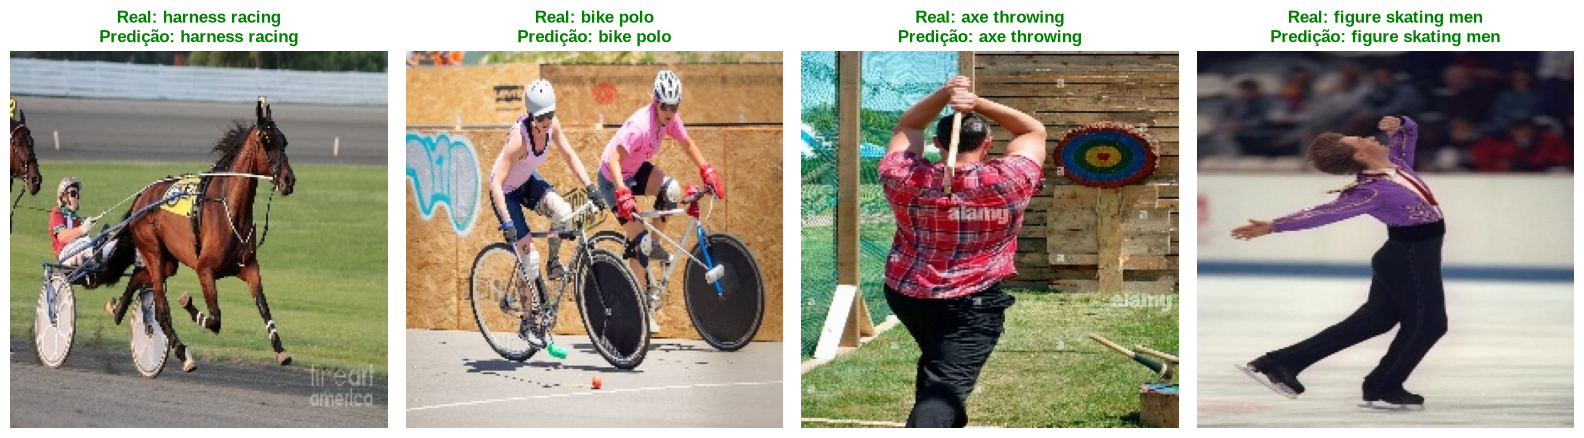

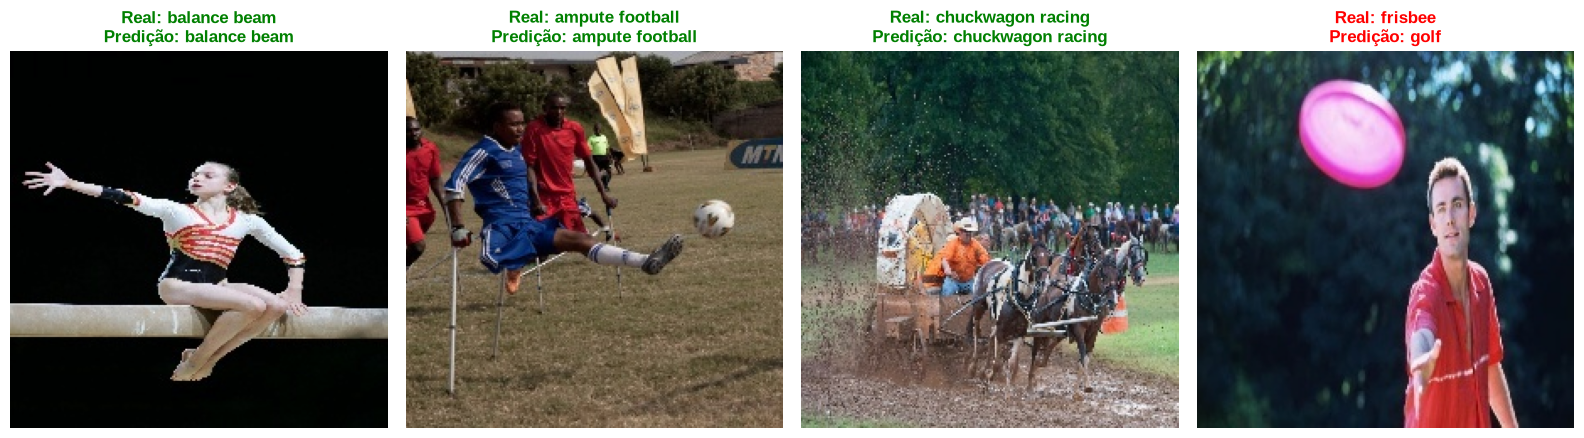

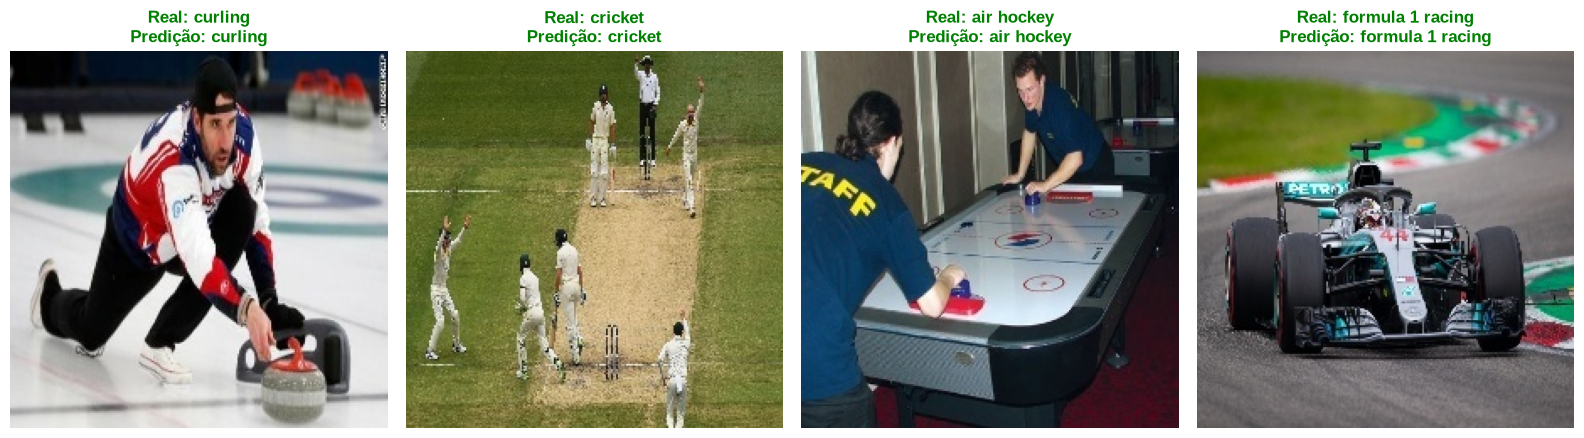

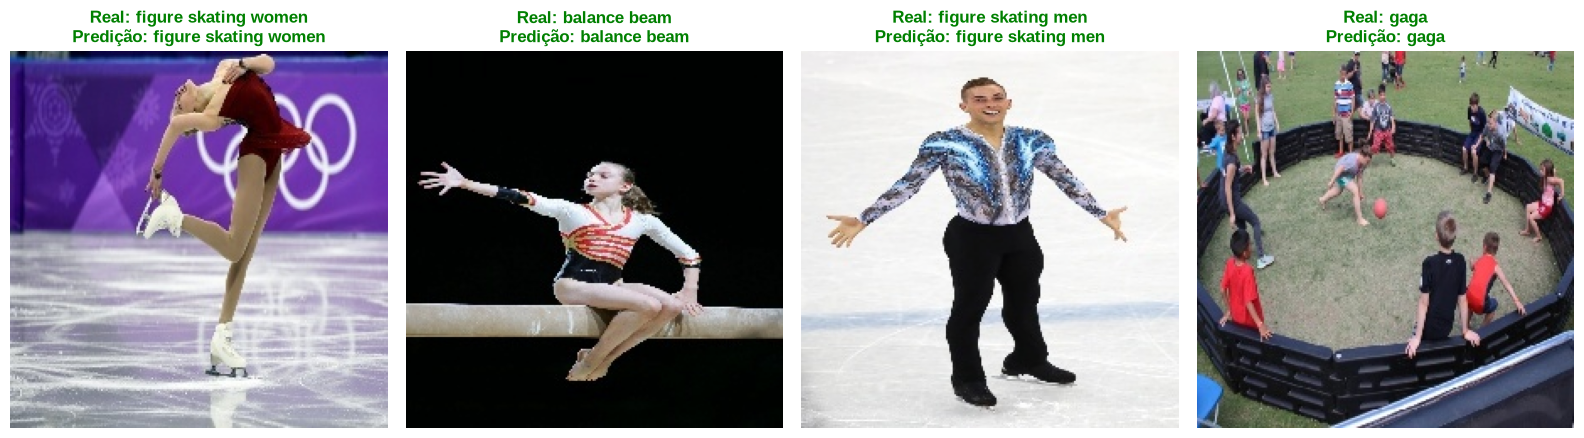

In [68]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def apresentar_amostras_teste(modelo, loader, dataset_classes, device, num_imagens=4):

    modelo.eval()


    imagens, rotulos = next(iter(loader))
    imagens_gpu = imagens.to(device)


    with torch.no_grad():
        saidas = modelo(imagens_gpu)
        predicoes = torch.argmax(saidas, dim=1)


    imagens = imagens.cpu()
    predicoes = predicoes.cpu()


    fig, axes = plt.subplots(1, num_imagens, figsize=(16, 5))

    for i in range(num_imagens):

        img = imagens[i].numpy().transpose((1, 2, 0))


        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)


        classe_real = dataset_classes[rotulos[i].item()]
        classe_predita = dataset_classes[predicoes[i].item()]


        axes[i].imshow(img)


        cor_texto = "green" if classe_real == classe_predita else "red"
        axes[i].set_title(f"Real: {classe_real}\nPredição: {classe_predita}",
                          color=cor_texto, fontweight='bold')
        axes[i].axis('off')

    plt.tight_layout()


    plt.savefig('amostras_teste_resultado.png', dpi=300, bbox_inches='tight')
    plt.show()


apresentar_amostras_teste(Anet, test_loader, test.classes, device)
apresentar_amostras_teste(Anet2,test_loader, test.classes, device)
apresentar_amostras_teste(netNiN,test_loader, test.classes, device)
apresentar_amostras_teste(netNiN2,test_loader, test.classes, device)

In [75]:
models = {
    "AlexNet": Anet,
    "AlexNet + Inception": Anet2,
    "NiN": netNiN,
    "NiN + Inception": netNiN2
}

resultados_acuracia= {}

for nome, modelo in models.items():
    modelo.to(device)
    modelo.eval()

    test_corrects=0
    test_total=0
    with torch.no_grad():
        for x_test, y_test in test_loader:
            x_test, y_test = x_test.to(device), y_test.to(device)

            # Faz a predição
            y_hat_test = modelo(x_test)
            predicoes = torch.argmax(y_hat_test, dim=1)

            # Contabiliza os acertos do lote
            test_corrects += torch.sum(predicoes == y_test).item()
            test_total += y_test.size(0)

    # Calcula a acurácia final do modelo e guarda no dicionário
    acc_final = (test_corrects / test_total) * 100
    resultados_acuracia[nome] = acc_final

    print(f"{nome} -> Acurácia no Teste: {acc_final:.2f}%")

AlexNet -> Acurácia no Teste: 85.50%
AlexNet + Inception -> Acurácia no Teste: 79.00%
NiN -> Acurácia no Teste: 81.50%
NiN + Inception -> Acurácia no Teste: 70.00%
